# Nuke Flavor and Domination Strategy

This notebook examines how domination strategy ratio predicts nuclear weapon flavor, using two model-control views for each outcome: combined player-type fixed effects and separated base-model/agentic-condition effects.

## Setup

In [17]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.formula.api import ols

from shared.plot_utilities import (
    load_panel_data,
    setup_notebook_display,
    deviation_coefficients,
    prepare_coefficient_data,
    plot_forest_plot
)
from shared.model_catalog import split_player_type

setup_notebook_display(figsize=(10, 6))

# Load panel data — exclude non-LLM experiments (vanilla-only, null-only)
panel_df = load_panel_data(
    '../panel_data.csv',
    exclude_non_llm=True,
)

# Keep only LLM players (Vanilla has no nuke/use_nuke data)
llm_df = panel_df[panel_df['player_type'] != 'Vanilla'].copy()
llm_df = llm_df.dropna(subset=['nuke', 'use_nuke', 'domination_ratio'])

player_type_parts = llm_df['player_type'].map(split_player_type)
llm_df['base_model'] = player_type_parts.map(lambda part: part['model_id'])
llm_df['agentic_condition'] = player_type_parts.map(lambda part: part['variant'])

# Reference player type for Treatment coding
reference_type = llm_df['player_type'].value_counts().idxmax()
reference_model = llm_df['base_model'].value_counts().idxmax()
reference_agentic_condition = llm_df['agentic_condition'].value_counts().idxmax()

print(f"\nAnalysis sample: {len(llm_df)} LLM-player observations")
print(f"Player types: {llm_df['player_type'].nunique()}  (reference: {reference_type})")
print(f"Base models: {llm_df['base_model'].nunique()}  (reference: {reference_model})")
print(f"Agentic conditions: {llm_df['agentic_condition'].nunique()}  (reference: {reference_agentic_condition})")
print(f"\nDescriptive statistics for key variables:")
llm_df[['nuke', 'use_nuke', 'domination_ratio']].describe().round(3)

✓ Loaded panel data: 2456 rows
✓ Filters applied: exclude_non_llm=True
✓ Unique conditions: 13
✓ Unique player types: 15

Player Type Distribution:
  Vanilla: 782 rows (31.8%)
  GLM-4.7-Simple: 179 rows (7.3%)
  GLM-4.7-Briefed: 179 rows (7.3%)
  Kimi-K2.5-Simple: 167 rows (6.8%)
  Kimi-K2.5-Briefed: 167 rows (6.8%)
  GPT-OSS-120B-Briefed: 156 rows (6.4%)
  GPT-OSS-120B-Simple: 156 rows (6.4%)
  Minimax-M2.5-Simple: 118 rows (4.8%)
  Minimax-M2.5-Briefed: 118 rows (4.8%)
  Deepseek-3.2-Briefed: 113 rows (4.6%)
  Deepseek-3.2-Simple: 113 rows (4.6%)
  Qwen-3.5-Briefed: 76 rows (3.1%)
  Qwen-3.5-Simple: 76 rows (3.1%)
  Sonnet-4.5-Briefed: 28 rows (1.1%)
  Sonnet-4.5-Simple: 28 rows (1.1%)

Condition Distribution:
  2026-deepseek-v-kimi2-v-glm-standard: 656 rows (26.7%)
  2026-oss-v-glm-standard: 528 rows (21.5%)
  2026-qwen-v-kimi2-v-minimax-standard: 328 rows (13.4%)
  2026-oss-v-qwen-v-minimax-standard: 280 rows (11.4%)
  2026-deepseek-v-kimi2-v-minimax-standard: 144 rows (5.9%)
  202

,nuke,use_nuke,domination_ratio
count,703.000,703.000,703.000
mean,52.535,43.347,0.159
std,33.476,31.311,0.281
min,0.000,0.000,0.000
25%,30.000,20.000,0.000
50%,50.000,40.000,0.000
75%,90.000,55.000,0.219
max,100.000,100.000,1.000


## 1. Nuclear Buildup Flavor

Outcome: `nuke`. The first model treats each `player_type` as its own fixed effect; the second decomposes `player_type` into `base_model` and `agentic_condition` (`Simple` or `Briefed`).

### 1a. Combined Player-Type Regression

**Model:** `nuke ~ domination_ratio + C(player_type)`

Coefficients are relative to the most-common player type reference. This is the original specification and keeps each model/condition pair as a separate category.

In [18]:
print("=" * 60)
print("OLS: nuke ~ domination_ratio + C(player_type)")
print("=" * 60)

formula_nuke = (
    'nuke ~ domination_ratio'
    f' + C(player_type, Treatment(reference="{reference_type}"))'
)
model_nuke = ols(formula_nuke, data=llm_df).fit()
print(model_nuke.summary())

OLS: nuke ~ domination_ratio + C(player_type)
                            OLS Regression Results                            
Dep. Variable:                   nuke   R-squared:                       0.464
Model:                            OLS   Adj. R-squared:                  0.453
Method:                 Least Squares   F-statistic:                     42.54
Date:                Mon, 13 Apr 2026   Prob (F-statistic):           1.71e-83
Time:                        14:23:45   Log-Likelihood:                -3245.9
No. Observations:                 703   AIC:                             6522.
Df Residuals:                     688   BIC:                             6590.
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                                                                                    coef    std err          t      P>|t|      [0.025      0.975]
------------------

### 1b. Combined Player-Type Effects Plot

Forest plot shows all player types as deviations from the grand mean, controlling for `domination_ratio`.


Player-Type Effects on Nuke Buildup Flavor
(deviation from grand mean, controlling for domination_ratio) SUMMARY

Baseline: Grand mean

Statistically Significant Effects (p < 0.05):
----------------------------------------
  Deepseek-3.2-Briefed           -17.390 [-25.550, -9.230] ***
  Deepseek-3.2-Simple            +18.495 [+10.747, +26.243] ***
  GLM-4.7-Briefed                +9.101 [+3.212, +14.989] **
  GLM-4.7-Simple                 +25.437 [+20.213, +30.660] ***
  GPT-OSS-120B-Briefed           -25.842 [-31.930, -19.753] ***
  GPT-OSS-120B-Simple            -25.982 [-31.896, -20.069] ***
  Kimi-K2.5-Briefed              +16.260 [+10.988, +21.532] ***
  Kimi-K2.5-Simple               +37.250 [+31.663, +42.836] ***
  Qwen-3.5-Briefed               -21.948 [-29.997, -13.898] ***
  Sonnet-4.5-Briefed             -33.140 [-48.342, -17.937] ***

Non-Significant Effects:
----------------------------------------
  Minimax-M2.5-Briefed           -0.022 [-6.970, +6.926]
  Minimax-M2.5-S

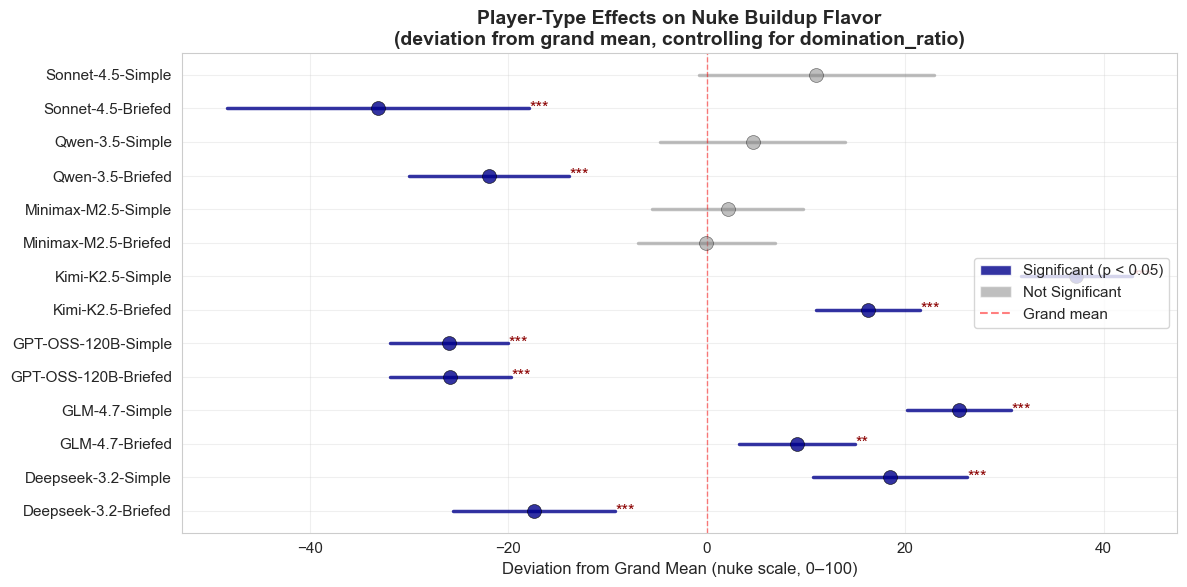


Domination ratio:  coef=+19.8243  95%CI=[+13.0417, +26.6069]  p=0.0000 ***
Interpretation: +0.1 in domination_ratio → +1.9824 change in nuke buildup flavor


In [19]:
pt_df = deviation_coefficients(model_nuke, reference_type)

fig, ax = plot_forest_plot(
    pt_df,
    title='Player-Type Effects on Nuke Buildup Flavor\n(deviation from grand mean, controlling for domination_ratio)',
    xlabel='Deviation from Grand Mean (nuke scale, 0–100)',
    color='darkblue',
    figsize=(12, 6),
    reference_line_label='Grand mean',
    use_prob_scale=False,
    sort_alphabetically=True,
)
plt.show()

params = model_nuke.params
conf_int = model_nuke.conf_int()
pvalues = model_nuke.pvalues
coef = params['domination_ratio']
ci = conf_int.loc['domination_ratio']
pval = pvalues['domination_ratio']
sig = '***' if pval < 0.001 else '**' if pval < 0.01 else '*' if pval < 0.05 else ''
print(f"\nDomination ratio:  coef={coef:+.4f}  95%CI=[{ci[0]:+.4f}, {ci[1]:+.4f}]  p={pval:.4f} {sig}")
print(f"Interpretation: +0.1 in domination_ratio → {coef*0.1:+.4f} change in nuke buildup flavor")

### 1c. Separated Base-Model and Agentic-Condition Regression

**Model:** `nuke ~ domination_ratio + C(base_model) + C(agentic_condition)`

This additive specification estimates base-model effects separately from the overall `Briefed` effect relative to `Simple`.

In [20]:
print("=" * 60)
print("OLS: nuke ~ domination_ratio + C(base_model) + C(agentic_condition)")
print("=" * 60)

formula_nuke_separated = (
    'nuke ~ domination_ratio'
    f' + C(base_model, Treatment(reference="{reference_model}"))'
    f' + C(agentic_condition, Treatment(reference="{reference_agentic_condition}"))'
)
model_nuke_separated = ols(formula_nuke_separated, data=llm_df).fit()
print(model_nuke_separated.summary())

OLS: nuke ~ domination_ratio + C(base_model) + C(agentic_condition)
                            OLS Regression Results                            
Dep. Variable:                   nuke   R-squared:                       0.430
Model:                            OLS   Adj. R-squared:                  0.423
Method:                 Least Squares   F-statistic:                     65.45
Date:                Mon, 13 Apr 2026   Prob (F-statistic):           1.08e-79
Time:                        14:23:46   Log-Likelihood:                -3267.5
No. Observations:                 703   AIC:                             6553.
Df Residuals:                     694   BIC:                             6594.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                                                      coef    std err          t      P>|t|      [0.025      0.975]
----------

### 1d. Separated Effects Plot

Forest plot shows the additive base-model coefficients and the `Briefed` coefficient relative to the dynamic reference levels.


Separated Effects on Nuke Buildup Flavor
(relative to base model and Simple references) SUMMARY

Baseline: Reference level

Statistically Significant Effects (p < 0.05):
----------------------------------------
  Briefed                        -16.210 [-20.061, -12.359] ***
  Deepseek-3.2                   -25.438 [-32.501, -18.374] ***
  GLM-4.7                        -9.233 [-14.771, -3.696] **
  GPT-OSS-120B                   -52.688 [-58.501, -46.874] ***
  Minimax-M2.5                   -24.932 [-31.537, -18.327] ***
  Qwen-3.5                       -36.027 [-43.572, -28.483] ***
  Sonnet-4.5                     -34.027 [-44.962, -23.091] ***

Overall Statistics:
----------------------------------------
  Total effects analyzed: 7
  Significant effects: 7 (100.0%)


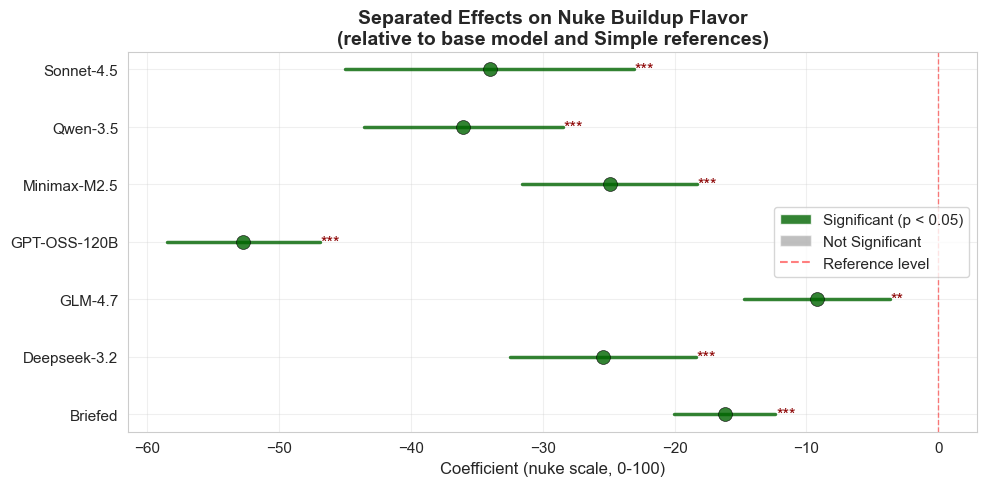

In [21]:
separated_nuke_terms = [
    term for term in model_nuke_separated.params.index
    if 'base_model' in term or 'agentic_condition' in term
]
separated_nuke_df = prepare_coefficient_data(
    model_nuke_separated.params,
    model_nuke_separated.conf_int(),
    model_nuke_separated.pvalues,
    separated_nuke_terms,
)

fig, ax = plot_forest_plot(
    separated_nuke_df,
    title='Separated Effects on Nuke Buildup Flavor\n(relative to base model and Simple references)',
    xlabel='Coefficient (nuke scale, 0-100)',
    color='darkgreen',
    figsize=(10, 5),
    reference_line_label='Reference level',
    use_prob_scale=False,
    sort_alphabetically=True,
)
plt.show()

## 2. Nuclear Usage Flavor

Outcome: `use_nuke`. The first model treats each `player_type` as its own fixed effect; the second decomposes `player_type` into `base_model` and `agentic_condition` (`Simple` or `Briefed`).

### 2a. Combined Player-Type Regression

**Model:** `use_nuke ~ domination_ratio + C(player_type)`

Coefficients are relative to the most-common player type reference. This is the original specification and keeps each model/condition pair as a separate category.

In [22]:
print("=" * 60)
print("OLS: use_nuke ~ domination_ratio + C(player_type)")
print("=" * 60)

formula_use = (
    'use_nuke ~ domination_ratio'
    f' + C(player_type, Treatment(reference="{reference_type}"))'
)
model_use = ols(formula_use, data=llm_df).fit()
print(model_use.summary())

OLS: use_nuke ~ domination_ratio + C(player_type)
                            OLS Regression Results                            
Dep. Variable:               use_nuke   R-squared:                       0.413
Model:                            OLS   Adj. R-squared:                  0.401
Method:                 Least Squares   F-statistic:                     34.59
Date:                Mon, 13 Apr 2026   Prob (F-statistic):           3.05e-70
Time:                        14:23:46   Log-Likelihood:                -3230.8
No. Observations:                 703   AIC:                             6492.
Df Residuals:                     688   BIC:                             6560.
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                                                                                    coef    std err          t      P>|t|      [0.025      0.975]
--------------

### 2b. Combined Player-Type Effects Plot

Forest plot shows all player types as deviations from the grand mean, controlling for `domination_ratio`.


Player-Type Effects on Nuke Usage Flavor
(deviation from grand mean, controlling for domination_ratio) SUMMARY

Baseline: Grand mean

Statistically Significant Effects (p < 0.05):
----------------------------------------
  Deepseek-3.2-Briefed           -10.420 [-18.406, -2.433] *
  Deepseek-3.2-Simple            +18.297 [+10.713, +25.880] ***
  GLM-4.7-Simple                 +13.486 [+8.373, +18.598] ***
  GPT-OSS-120B-Briefed           -21.542 [-27.501, -15.583] ***
  GPT-OSS-120B-Simple            -21.621 [-27.409, -15.834] ***
  Kimi-K2.5-Briefed              +13.762 [+8.601, +18.922] ***
  Kimi-K2.5-Simple               +34.001 [+28.533, +39.469] ***
  Minimax-M2.5-Briefed           +8.231 [+1.431, +15.032] *
  Minimax-M2.5-Simple            +8.313 [+0.887, +15.738] *
  Qwen-3.5-Briefed               -16.972 [-24.851, -9.093] ***
  Sonnet-4.5-Briefed             -29.654 [-44.533, -14.774] ***

Non-Significant Effects:
----------------------------------------
  GLM-4.7-Briefed    

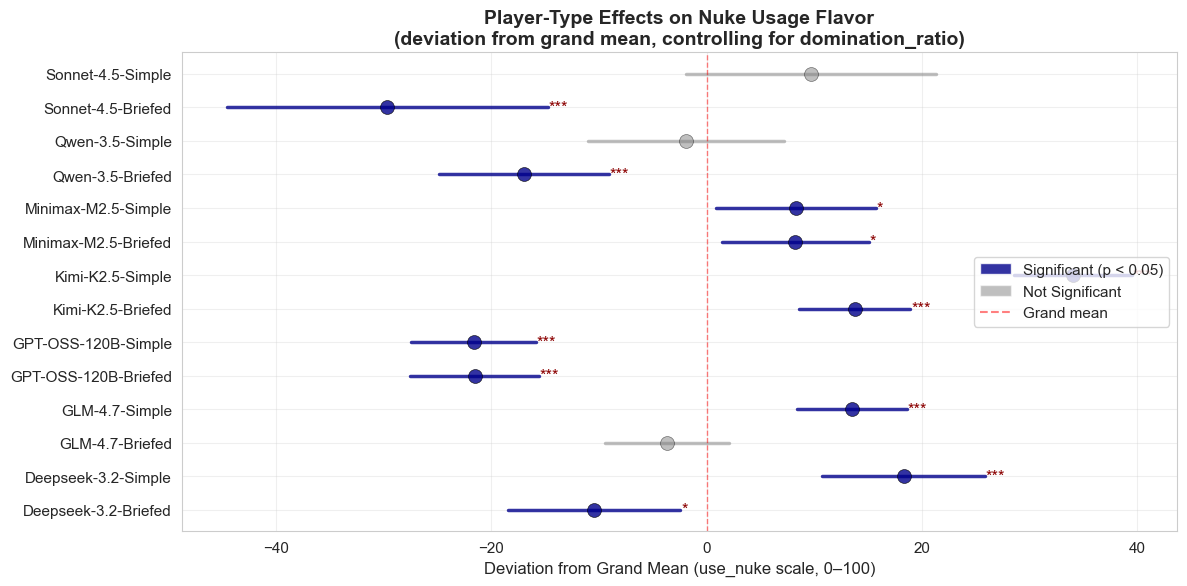


Domination ratio:  coef=+25.0929  95%CI=[+18.4544, +31.7313]  p=0.0000 ***
Interpretation: +0.1 in domination_ratio → +2.5093 change in nuke usage flavor


In [23]:
pt_df = deviation_coefficients(model_use, reference_type)

fig, ax = plot_forest_plot(
    pt_df,
    title='Player-Type Effects on Nuke Usage Flavor\n(deviation from grand mean, controlling for domination_ratio)',
    xlabel='Deviation from Grand Mean (use_nuke scale, 0–100)',
    color='darkblue',
    figsize=(12, 6),
    reference_line_label='Grand mean',
    use_prob_scale=False,
    sort_alphabetically=True,
)
plt.show()

params = model_use.params
conf_int = model_use.conf_int()
pvalues = model_use.pvalues
coef = params['domination_ratio']
ci = conf_int.loc['domination_ratio']
pval = pvalues['domination_ratio']
sig = '***' if pval < 0.001 else '**' if pval < 0.01 else '*' if pval < 0.05 else ''
print(f"\nDomination ratio:  coef={coef:+.4f}  95%CI=[{ci[0]:+.4f}, {ci[1]:+.4f}]  p={pval:.4f} {sig}")
print(f"Interpretation: +0.1 in domination_ratio → {coef*0.1:+.4f} change in nuke usage flavor")

### 2c. Separated Base-Model and Agentic-Condition Regression

**Model:** `use_nuke ~ domination_ratio + C(base_model) + C(agentic_condition)`

This additive specification estimates base-model effects separately from the overall `Briefed` effect relative to `Simple`.

In [24]:
print("=" * 60)
print("OLS: use_nuke ~ domination_ratio + C(base_model) + C(agentic_condition)")
print("=" * 60)

formula_use_separated = (
    'use_nuke ~ domination_ratio'
    f' + C(base_model, Treatment(reference="{reference_model}"))'
    f' + C(agentic_condition, Treatment(reference="{reference_agentic_condition}"))'
)
model_use_separated = ols(formula_use_separated, data=llm_df).fit()
print(model_use_separated.summary())

OLS: use_nuke ~ domination_ratio + C(base_model) + C(agentic_condition)
                            OLS Regression Results                            
Dep. Variable:               use_nuke   R-squared:                       0.384
Model:                            OLS   Adj. R-squared:                  0.377
Method:                 Least Squares   F-statistic:                     54.05
Date:                Mon, 13 Apr 2026   Prob (F-statistic):           4.18e-68
Time:                        14:23:46   Log-Likelihood:                -3247.9
No. Observations:                 703   AIC:                             6514.
Df Residuals:                     694   BIC:                             6555.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                                                      coef    std err          t      P>|t|      [0.025      0.975]
------

### 2d. Separated Effects Plot

Forest plot shows the additive base-model coefficients and the `Briefed` coefficient relative to the dynamic reference levels.


Separated Effects on Nuke Usage Flavor
(relative to base model and Simple references) SUMMARY

Baseline: Reference level

Statistically Significant Effects (p < 0.05):
----------------------------------------
  Briefed                        -14.159 [-17.904, -10.413] ***
  Deepseek-3.2                   -19.303 [-26.172, -12.434] ***
  GLM-4.7                        -18.494 [-23.879, -13.109] ***
  GPT-OSS-120B                   -45.435 [-51.089, -39.782] ***
  Minimax-M2.5                   -14.789 [-21.213, -8.366] ***
  Qwen-3.5                       -33.195 [-40.532, -25.858] ***
  Sonnet-4.5                     -30.421 [-41.056, -19.786] ***

Overall Statistics:
----------------------------------------
  Total effects analyzed: 7
  Significant effects: 7 (100.0%)


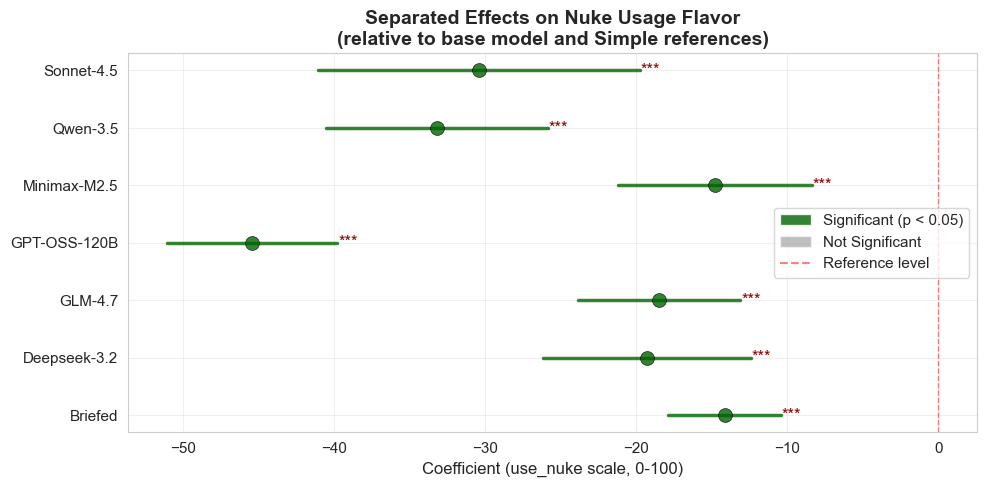

In [25]:
separated_use_terms = [
    term for term in model_use_separated.params.index
    if 'base_model' in term or 'agentic_condition' in term
]
separated_use_df = prepare_coefficient_data(
    model_use_separated.params,
    model_use_separated.conf_int(),
    model_use_separated.pvalues,
    separated_use_terms,
)

fig, ax = plot_forest_plot(
    separated_use_df,
    title='Separated Effects on Nuke Usage Flavor\n(relative to base model and Simple references)',
    xlabel='Coefficient (use_nuke scale, 0-100)',
    color='darkgreen',
    figsize=(10, 5),
    reference_line_label='Reference level',
    use_prob_scale=False,
    sort_alphabetically=True,
)
plt.show()